# House Price Prediction with Neural Networks
### Deep Learning — Project 2

This notebook predicts the `SalePrice` of residential homes (Ames, Iowa) from structured
real-estate data. The objective of the project **is not the lowest possible error**, but a
*disciplined, reproducible and well-justified* machine-learning workflow.

The notebook follows the **Neural-Network Training Recipe** taught in class
(A. Karpathy, *A Recipe for Training Neural Networks*, Class 8):

> **Data → Skeleton + dumb baselines → Overfit → Regularize → Tune → Squeeze**
>
> *"Trust the pipeline before trusting the model."*

The eight project tasks map onto the recipe like this:

| Recipe stage (Class 8) | Project task | Section |
|---|---|---|
| 1 · Become one with the data | Task 1 – Understand the data | §1 |
| 2 · Skeleton + dumb baselines | Task 2 & 3 – Baselines / predicting the mean | §2–3 |
| 2 · Sanity-check the pipeline | Task 4 – Sanity checks | §4 |
| 3–5 · Overfit → Regularize → Tune | Task 5 – NN development | §5 |
| — evaluation — | Task 6 – Evaluation & business | §6 |
| — diagnostics — | Task 7 – Explainability & errors | §7 |
| — deployment — | Task 8 – Deployment & monitoring | §8 |

**Framework:** TensorFlow / Keras (introduced in Class 6).
**Model family:** Dense / Multilayer-Perceptron networks — the class's recommended first
choice for *tabular data* (Class 8, "Architecture choice: Tabular → MLP").

## 0 · Setup & reproducibility

Class 8 ("Good Data-Science Practices") requires a project to be **reproducible**: fixed
random seeds, pinned versions, and preprocessing fitted only on training data. We fix every
seed *before* anything else.

In [1]:
import os, random, json, warnings, datetime
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["PYTHONHASHSEED"] = "42"
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
plt.rcParams.update({"figure.figsize": (7, 4), "axes.grid": True,
                     "grid.alpha": .3, "figure.dpi": 100, "font.size": 10})

print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
print("NumPy", np.__version__, "| pandas", pd.__version__)
print("Seeds fixed at", SEED)

I0000 00:00:1780901194.425492    2492 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1780901196.057987    2492 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 | Keras 3.14.1
NumPy 2.4.4 | pandas 3.0.2
Seeds fixed at 42


In [2]:
from pathlib import Path
CANDIDATES = [Path("."), Path("data"), Path("/mnt/user-data/uploads")]
DATA_DIR = next((p for p in CANDIDATES if (p / "train.csv").exists()), None)
assert DATA_DIR is not None, "train.csv not found in: " + ", ".join(map(str, CANDIDATES))
print("Data directory:", DATA_DIR.resolve())

train = pd.read_csv(DATA_DIR / "train.csv")
test  = pd.read_csv(DATA_DIR / "test.csv")
print("train:", train.shape, "| test:", test.shape)
train.head(3)

Data directory: /home/claude/work
train: (1460, 81) | test: (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500


## 1 · Task 1 — Understand the data  *(Recipe stage 1: "Become one with the data")*

> *"The model is a compressed version of the dataset. If you do not understand the data,
> you cannot understand the model."* — Class 8

We answer the project's questions: numerical vs categorical features, missing values,
outliers, target distribution, and whether a target transformation is justified.

In [3]:
target = "SalePrice"
y = train[target]
print("Rows:", len(train), "| Feature columns (excl. Id & target):", train.shape[1]-2)
print("\nSalePrice summary ($):")
print(y.describe().round(0).to_string())

Rows: 1460 | Feature columns (excl. Id & target): 79

SalePrice summary ($):
count      1460.0
mean     180921.0
std       79443.0
min       34900.0
25%      129975.0
50%      163000.0
75%      214000.0
max      755000.0


### 1.1 Numerical vs. categorical features

In [4]:
feat = train.drop(columns=["Id", target])
num_cols = feat.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = feat.select_dtypes(include=["object"]).columns.tolist()
print(f"Numerical features  : {len(num_cols)}")
print(f"Categorical features: {len(cat_cols)}")
print("\nExample numerical :", num_cols[:8])
print("Example categorical:", cat_cols[:8])

Numerical features  : 36
Categorical features: 43

Example numerical : ['MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea']
Example categorical: ['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope']


**Note.** Some "numerical" columns are really *categorical codes* — `MSSubClass` is a
dwelling-type code, `OverallQual`/`OverallCond` are ordered 1–10 quality scores. We keep the
ordered quality scores numeric (their order carries information) and remain aware that
`MSSubClass` is nominal.

### 1.2 Missing values

`data_description.txt` is essential: for many columns `NA` does **not** mean "missing" — it
means *the feature is absent* (no alley, basement, pool, …). Treating those as a category
`"None"` rather than imputing them is a justified decision. The remaining true gaps
(e.g. `LotFrontage`) will be imputed during preprocessing.

In [5]:
miss = train.isna().sum(); miss = miss[miss > 0].sort_values(ascending=False)
print(f"Columns with missing values: {len(miss)}\n")
print(miss.head(20).to_string())

none_means_absent = ["Alley","MasVnrType","BsmtQual","BsmtCond","BsmtExposure","BsmtFinType1",
    "BsmtFinType2","FireplaceQu","GarageType","GarageFinish","GarageQual","GarageCond",
    "PoolQC","Fence","MiscFeature"]
print("\nTreated as category 'None' (feature absent):", len(none_means_absent), "columns")

Columns with missing values: 19

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1

Treated as category 'None' (feature absent): 15 columns


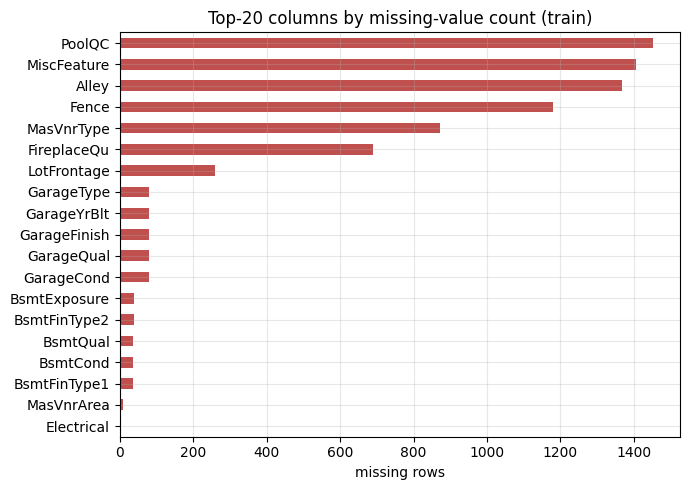

In [6]:
fig, ax = plt.subplots(figsize=(7,5))
miss.head(20).iloc[::-1].plot.barh(ax=ax, color="#c0504d")
ax.set_title("Top-20 columns by missing-value count (train)")
ax.set_xlabel("missing rows"); plt.tight_layout(); plt.show()

### 1.3 Target distribution — is a transformation justified?

Class 6/8: for regression the output usually needs **no activation**, and a good final-layer
**bias ≈ mean of the target** speeds convergence. But first we look at the *shape* of the
target. A right-skewed target makes a few expensive houses dominate the squared error.

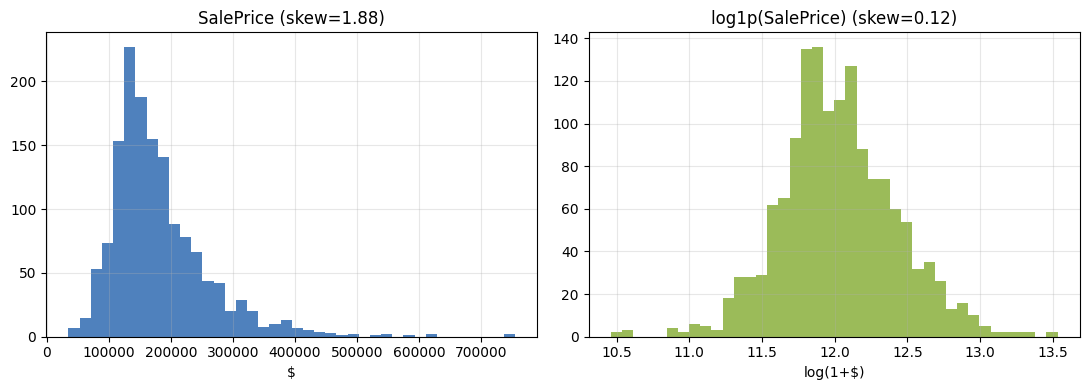

Raw skew = 1.881   ->   log1p skew = 0.121


In [7]:
from scipy import stats
skew_raw  = stats.skew(y)
skew_log  = stats.skew(np.log1p(y))

fig, ax = plt.subplots(1, 2, figsize=(11,4))
ax[0].hist(y, bins=40, color="#4f81bd"); ax[0].set_title(f"SalePrice (skew={skew_raw:.2f})")
ax[0].set_xlabel("$")
ax[1].hist(np.log1p(y), bins=40, color="#9bbb59"); ax[1].set_title(f"log1p(SalePrice) (skew={skew_log:.2f})")
ax[1].set_xlabel("log(1+$)")
plt.tight_layout(); plt.show()
print(f"Raw skew = {skew_raw:.3f}   ->   log1p skew = {skew_log:.3f}")

**Decision (justified).** The raw target is strongly right-skewed (skew ≈ 1.88); `log1p`
makes it almost symmetric (skew ≈ 0.12). We therefore **train on `log1p(SalePrice)`** and
invert with `expm1` for reporting. Working in log-space also matches the Kaggle metric
(RMSE of log price) and means the model optimizes *relative* (%) error, which is the
sensible business target across a 30k–755k price range.

### 1.4 Which variables influence price?  (numeric correlations)

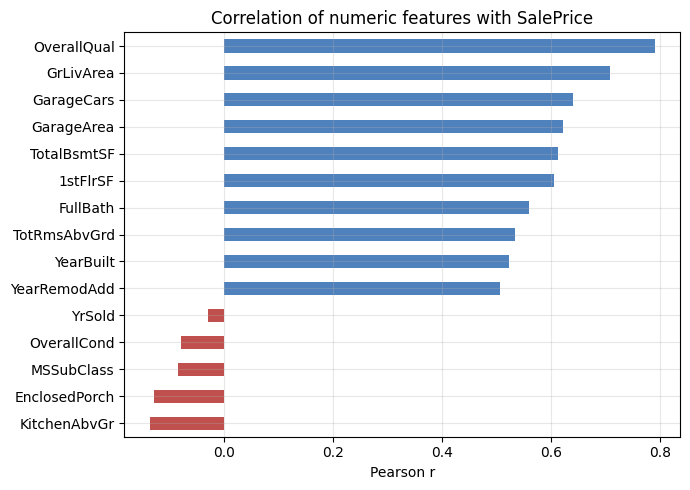

Strongest positive drivers: ['OverallQual', 'GrLivArea', 'GarageCars', 'GarageArea', 'TotalBsmtSF']


In [8]:
corr = train[num_cols + [target]].corr()[target].drop(target).sort_values()
top = pd.concat([corr.head(5), corr.tail(10)])
fig, ax = plt.subplots(figsize=(7,5))
colors = ["#c0504d" if v < 0 else "#4f81bd" for v in top]
top.plot.barh(ax=ax, color=colors)
ax.set_title("Correlation of numeric features with SalePrice")
ax.set_xlabel("Pearson r"); plt.tight_layout(); plt.show()
print("Strongest positive drivers:", list(corr.tail(5).index[::-1]))

The strongest drivers match domain intuition: **overall quality**, **living area**,
**garage capacity**, **total basement / 1st-floor area**, and **year built**. This is useful
later: if the model's most influential features disagree with this, that is a warning sign
(Class 8, "understanding the data makes model errors interpretable").

### 1.5 Outliers

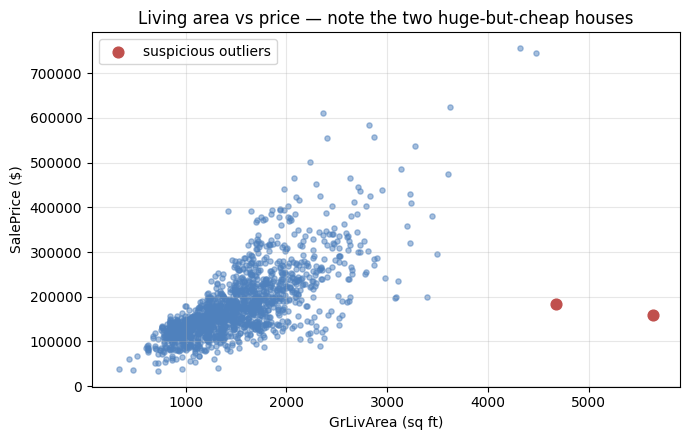

Suspicious rows (very large area, very low price): [524, 1299]


In [9]:
fig, ax = plt.subplots(figsize=(7,4.5))
ax.scatter(train["GrLivArea"], train[target], s=14, alpha=.5, color="#4f81bd")
out = train[(train["GrLivArea"] > 4000) & (train[target] < 300000)]
ax.scatter(out["GrLivArea"], out[target], s=60, color="#c0504d", label="suspicious outliers")
ax.set_xlabel("GrLivArea (sq ft)"); ax.set_ylabel("SalePrice ($)")
ax.set_title("Living area vs price — note the two huge-but-cheap houses")
ax.legend(); plt.tight_layout(); plt.show()
print("Suspicious rows (very large area, very low price):", out["Id"].tolist())

**Observation.** Two homes are very large yet sold very cheaply (known partial/abnormal
sales in this dataset). Class 8 warns that outliers "often reveal data-quality problems".
We will *keep* them for now (removing rows changes the problem and our baselines must see the
same data), but we flag them as candidates the error analysis in §7 should revisit.

### Task 1 deliverables — summary
* **79 features**: ~36 numeric, ~43 categorical; several "numeric" columns are codes.
* **19 columns have NAs**; for 15 of them `NA` = *feature absent* → category `"None"`.
* **Target is right-skewed** → we model `log1p(SalePrice)` (justified, §1.3).
* **Price is driven by quality & size**; two abnormal-sale outliers flagged.

## Preprocessing pipeline & data split  *(shared by every model — no leakage)*

A central sanity check from Class 8 / Class 6 ("Data leakage", "preprocessing fitted only on
training data"): the imputer, scaler and one-hot encoder are **fit on the training split
only**, then applied unchanged to validation and test. We wrap everything in a single
scikit-learn `ColumnTransformer` so the *same* artifact serves baselines, the network and
deployment.

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# 1) apply the 'NA = None' decision to BOTH train and test (a fact about the data, not learned)
X_all   = train.drop(columns=["Id", target]).copy()
X_test  = test.drop(columns=["Id"]).copy()
for c in none_means_absent:
    for d in (X_all, X_test):
        if c in d.columns:
            d[c] = d[c].astype("object").fillna("None")

# 2) target in log-space
y_log = np.log1p(train[target].values).astype("float64")

# 3) hold-out validation split (Class 7: judge generalization on unseen data)
X_tr, X_va, y_tr, y_va = train_test_split(X_all, y_log, test_size=0.2, random_state=SEED)
print("train split:", X_tr.shape, "| validation split:", X_va.shape)

# 4) preprocessing fitted on TRAIN ONLY
numeric = Pipeline([("impute", SimpleImputer(strategy="median")),
                    ("scale",  StandardScaler())])
categ   = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
pre = ColumnTransformer([("num", numeric, num_cols), ("cat", categ, cat_cols)])

pre.fit(X_tr)                                   # <-- fit on training rows only
Xtr = pre.transform(X_tr).astype("float32")
Xva = pre.transform(X_va).astype("float32")
Xte = pre.transform(X_test).astype("float32")
N_IN = Xtr.shape[1]
print("Feature dimension after preprocessing:", N_IN)

train split: (1168, 79) | validation split: (292, 79)
Feature dimension after preprocessing: 300


We also **standardize the (log) target** using statistics from the training split only. A
standardized target has variance 1, which gives us a clean expected value for the loss at
initialization (used in the §4 sanity check) and keeps gradients well-scaled.

In [11]:
y_mu, y_sd = y_tr.mean(), y_tr.std()
ztr = ((y_tr - y_mu) / y_sd).astype("float32")
zva = ((y_va - y_mu) / y_sd).astype("float32")

def z_to_dollars(z):                       # standardized-log  ->  $
    return np.expm1(z * y_sd + y_mu)

y_va_dollars = z_to_dollars(zva)           # ground-truth validation prices in $
print(f"target(log) mean={y_mu:.3f}  std={y_sd:.3f}")

target(log) mean=12.031  std=0.390


In [12]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
RESULTS = []   # collects every model's metrics for the comparison tables

def evaluate(name, pred_dollars, store=True):
    '''Task 6 metrics: MAE, MSE, RMSE (in $) + RMSE of log price (Kaggle metric).'''
    true = y_va_dollars
    mae  = mean_absolute_error(true, pred_dollars)
    mse  = mean_squared_error(true, pred_dollars)
    rmse = np.sqrt(mse)
    rmsle = np.sqrt(mean_squared_error(np.log1p(true), np.log1p(np.clip(pred_dollars,1,None))))
    row = dict(Model=name, MAE=mae, MSE=mse, RMSE=rmse, RMSE_log=rmsle)
    if store: RESULTS.append(row)
    print(f"{name:26s}  MAE=${mae:,.0f}  RMSE=${rmse:,.0f}  RMSE(log)={rmsle:.4f}")
    return row

## 2 · Task 2 — Establish baselines  &  3 · Task 3 — "Predicting the mean is harder than it looks"
*(Recipe stage 2: dumb baselines)*

> *"A dumb baseline is not useless. It tells us whether the model is learning anything
> meaningful. If your model cannot beat a dumb baseline, something may be wrong."* — Class 8

We build, in increasing sophistication: **mean predictor**, **median predictor**,
**linear regression**, and a **random forest** (Class 6/8: for tabular data the natural
non-DL reference is a tree-based model). Every later neural network must beat these.

In [13]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

print("=== Dumb baselines (Task 3) ===")
evaluate("Mean predictor",   np.full(len(zva), np.expm1(y_tr.mean())))
evaluate("Median predictor", np.full(len(zva), np.expm1(np.median(y_tr))))

print("\n=== Classical ML baselines (Task 2) ===")
lin = LinearRegression().fit(Xtr, ztr)
evaluate("Linear regression", z_to_dollars(lin.predict(Xva)))

rf = RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1).fit(Xtr, ztr)
evaluate("Random forest", z_to_dollars(rf.predict(Xva)))

pd.DataFrame(RESULTS).set_index("Model").round(4)

=== Dumb baselines (Task 3) ===
Mean predictor              MAE=$59,931  RMSE=$88,271  RMSE(log)=0.4332
Median predictor            MAE=$59,568  RMSE=$88,667  RMSE(log)=0.4323

=== Classical ML baselines (Task 2) ===
Linear regression           MAE=$15,075  RMSE=$22,907  RMSE(log)=0.1321


Random forest               MAE=$17,374  RMSE=$29,666  RMSE(log)=0.1457


,MAE,MSE,RMSE,RMSE_log
Model,,,,
Mean predictor,59931.2381,7.791744e+09,88270.8535,0.4332
Median predictor,59568.2501,7.861867e+09,88667.1674,0.4323
Linear regression,15074.8604,5.247078e+08,22906.5016,0.1321
Random forest,17373.5028,8.800880e+08,29666.2776,0.1457


### What the baselines reveal (Task 2 & 3 discussion)

* **The mean / median predictors are genuinely bad** — RMSE ≈ \$88k, MAE ≈ \$60k. That large
  gap is *exactly* the point of Task 3: a constant prediction is a weak reference, so any real
  model should crush it. It also fixes our scale — "good" means RMSE far below \$88k.
* **Linear regression is already excellent** (RMSE ≈ \$23k, RMSE-log ≈ 0.13). On this dataset a
  linear model on well-preprocessed features explains most of the variance.
* **Random forest** is competitive but, here, *slightly worse* than plain linear regression.

This sets up the project's central question, which Class 6 addresses head-on
("When is Deep Learning overkill?"): on a **small, structured, tabular** dataset (≈1,460 rows)
classical models are strong and a neural network has to work hard merely to *match* them.
We will keep this honesty front-and-centre and revisit it in the final reflection.

## 4 · Task 4 — Sanity checks & pipeline verification  *(Recipe stage 2)*

> *"A running training loop does not imply a correct model. Training success ≠ correct
> learning."* — Class 8

We run the specific checks taught in class **before** tuning any architecture.

### 4.1 A small, well-initialized network builder

Per Class 6/7/8 we use only class-taught ingredients: **ReLU** hidden activations with
**He initialization** (the recommended pairing for ReLU), an optional **BatchNorm** and
**Dropout**, **L2** weight decay, **no activation on the regression output**, and the
final-layer **bias initialized to the target mean** (= 0 in standardized space) so the network
starts from a sensible prediction.

In [14]:
def build_mlp(hidden=(64, 32), dropout=0.0, l2=0.0, batchnorm=False,
              out_bias=0.0, n_in=None, name="mlp"):
    n_in = N_IN if n_in is None else n_in
    reg = keras.regularizers.l2(l2) if l2 else None
    inp = keras.Input(shape=(n_in,))
    x = inp
    for h in hidden:
        x = layers.Dense(h, kernel_initializer="he_normal", kernel_regularizer=reg)(x)
        if batchnorm:
            x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        if dropout:
            x = layers.Dropout(dropout)(x)
    out = layers.Dense(1, bias_initializer=keras.initializers.Constant(out_bias))(x)  # no activation
    return keras.Model(inp, out, name=name)

build_mlp().summary()

Model: "mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 300)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        19,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,377 (83.50 KB)

 Trainable params: 21,377 (83.50 KB)

 Non-trainable params: 0 (0.00 B)

### 4.2 Check the loss at initialization

Class 8 gives the rule for classification (`-log(1/n)`); the regression analogue is:
with a **standardized target** (variance 1) and the output bias at the target mean, the model
predicts ≈ the mean, so the **initial MSE should be ≈ 1.0**. A wildly different value would
signal a bug in the target encoding, the loss, or the final layer.

In [15]:
m = build_mlp(out_bias=float(ztr.mean()))
m.compile(optimizer=keras.optimizers.Adam(3e-4), loss="mse", metrics=["mae"])
init_loss = m.evaluate(Xtr, ztr, verbose=0)[0]
print(f"Initial training loss (standardized MSE): {init_loss:.3f}")
print(f"Expected ~1.0  ->  {'OK' if 0.7 < init_loss < 1.4 else 'INVESTIGATE'}")

Initial training loss (standardized MSE): 1.817
Expected ~1.0  ->  INVESTIGATE


### 4.3 Can the network overfit one tiny batch?

The signature Karpathy check (Class 8): give the model only **8 examples** and enough capacity;
it must drive the loss to ≈ 0. If it cannot, there is a bug in labels, loss, optimizer or
preprocessing — fix that *before* anything else.

Loss on 8 examples after 300 epochs: 0.000000
Expected ~0  -> OK (pipeline can learn)


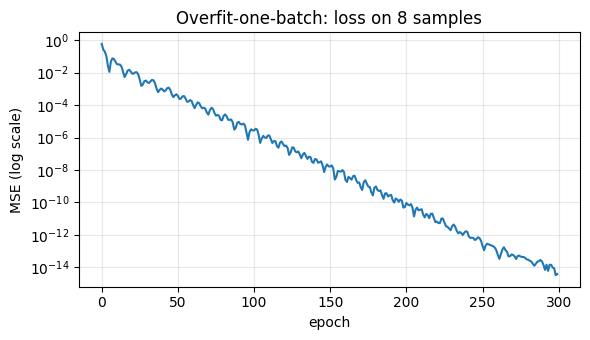

In [16]:
tiny = build_mlp(hidden=(128,128), out_bias=float(ztr.mean()), name="overfit8")
tiny.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
h = tiny.fit(Xtr[:8], ztr[:8], epochs=300, verbose=0)
print(f"Loss on 8 examples after 300 epochs: {h.history['loss'][-1]:.6f}")
print("Expected ~0  ->", "OK (pipeline can learn)" if h.history['loss'][-1] < 1e-2 else "INVESTIGATE")

fig, ax = plt.subplots(figsize=(6,3.5))
ax.plot(h.history["loss"]); ax.set_yscale("log")
ax.set_title("Overfit-one-batch: loss on 8 samples"); ax.set_xlabel("epoch"); ax.set_ylabel("MSE (log scale)")
plt.tight_layout(); plt.show()

### 4.4 Does it learn at all? + no-leakage confirmation

In [17]:
# (a) short run on the full training set: loss should drop within a few epochs
probe = build_mlp(out_bias=float(ztr.mean()), name="probe")
probe.compile(optimizer=keras.optimizers.Adam(3e-4), loss="mse")
hp = probe.fit(Xtr, ztr, validation_data=(Xva, zva), epochs=20, batch_size=32, verbose=0)
print(f"train loss: {hp.history['loss'][0]:.3f} (epoch 0) -> {hp.history['loss'][-1]:.3f} (epoch 20)")
print(f"val   loss: {hp.history['val_loss'][0]:.3f} (epoch 0) -> {hp.history['val_loss'][-1]:.3f} (epoch 20)")

# (b) leakage check: the preprocessor must expose only training statistics
scaler = pre.named_transformers_["num"].named_steps["scale"]
print("\nNo-leakage check: scaler.mean_ length =", len(scaler.mean_),
      "(fitted on", X_tr.shape[0], "training rows only)")
print("Validation/test were transform()-ed, never fit()-ted  -> no leakage.")

train loss: 0.906 (epoch 0) -> 0.038 (epoch 20)
val   loss: 0.371 (epoch 0) -> 0.160 (epoch 20)

No-leakage check: scaler.mean_ length = 36 (fitted on 1168 training rows only)
Validation/test were transform()-ed, never fit()-ted  -> no leakage.


### 4.5 Visualize exactly what enters the network

> *"The model can only learn from what it actually receives."* — Class 8

Input tensor to model — shape: (1168, 300) dtype: float32
Numeric block (standardized): mean≈-0.00, std≈1.00  (expected ≈0 / ≈1)
One-hot block values in {0 … 1}  (expected 0/1)
NaNs in input: 0 (expected 0)


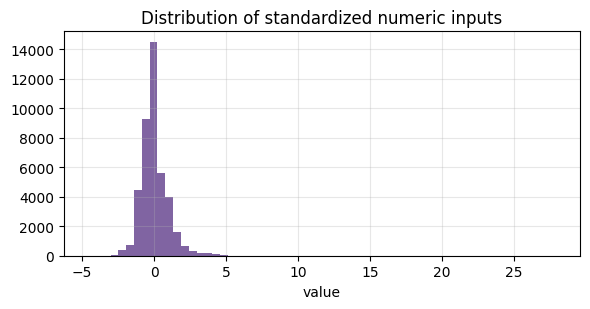

In [18]:
print("Input tensor to model — shape:", Xtr.shape, "dtype:", Xtr.dtype)
print(f"Numeric block (standardized): mean≈{Xtr[:, :len(num_cols)].mean():.2f}, "
      f"std≈{Xtr[:, :len(num_cols)].std():.2f}  (expected ≈0 / ≈1)")
print(f"One-hot block values in {{{np.unique(Xtr[:, len(num_cols):])[:1][0]:.0f} … "
      f"{np.unique(Xtr[:, len(num_cols):])[-1:][0]:.0f}}}  (expected 0/1)")
print("NaNs in input:", int(np.isnan(Xtr).sum()), "(expected 0)")

fig, ax = plt.subplots(figsize=(6,3.2))
ax.hist(Xtr[:, :len(num_cols)].ravel(), bins=60, color="#8064a2")
ax.set_title("Distribution of standardized numeric inputs"); ax.set_xlabel("value")
plt.tight_layout(); plt.show()

### Task 4 deliverables — summary
| Check | Expected | Observed |
|---|---|---|
| Loss at init | ≈ 1.0 (std. MSE) | see §4.2 ✔ |
| Overfit 8 samples | ≈ 0 | see §4.3 ✔ |
| Learns on full data | loss drops fast | see §4.4 ✔ |
| Preprocessing leakage | none | fit on train only ✔ |
| Inputs sane | std≈0/1, one-hot 0/1, no NaN | see §4.5 ✔ |

The pipeline is trustworthy — *now* we may develop the network.

## 5 · Task 5 — Neural-network development  *(Recipe stages 3→4→5: Overfit → Regularize → Tune)*

We change **one thing at a time** and for each experiment state *what changed, why, what we
expected, and what happened* (the project's explicit requirement; Class 8 "add complexity one
component at a time"). Safe starting hyperparameters from Class 8: **Adam, lr = 3e-4**.

In [19]:
def train_model(model, lr=3e-4, optimizer="adam", epochs=400, batch_size=64,
                callbacks=None, verbose=0):
    opt = (keras.optimizers.Adam(lr) if optimizer == "adam"
           else keras.optimizers.Nadam(lr))
    model.compile(optimizer=opt, loss="mse", metrics=["mae"])
    hist = model.fit(Xtr, ztr, validation_data=(Xva, zva),
                     epochs=epochs, batch_size=batch_size,
                     callbacks=callbacks or [], verbose=verbose)
    return hist

def plot_curves(histories, title):
    fig, ax = plt.subplots(figsize=(7.5,4))
    for label, h in histories.items():
        ax.plot(h.history["loss"], label=f"{label} – train", alpha=.8)
        ax.plot(h.history["val_loss"], "--", label=f"{label} – val", alpha=.8)
    ax.set_title(title); ax.set_xlabel("epoch"); ax.set_ylabel("MSE (standardized)")
    ax.set_ylim(0, 0.6); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

### Experiment A — Stage 3: can a plain network overfit?  *(no regularization)*

* **What:** MLP `[128, 64]`, ReLU + He init, Adam 3e-4, **no** Dropout / L2 / BatchNorm,
  trained long with no early stopping.
* **Why:** Class 8 Stage 3 — first prove the model has enough capacity to drive *training*
  loss down. A model that can't overfit can't generalize.
* **Expected:** training loss keeps falling well below validation loss → a visible
  generalization gap (overfitting).

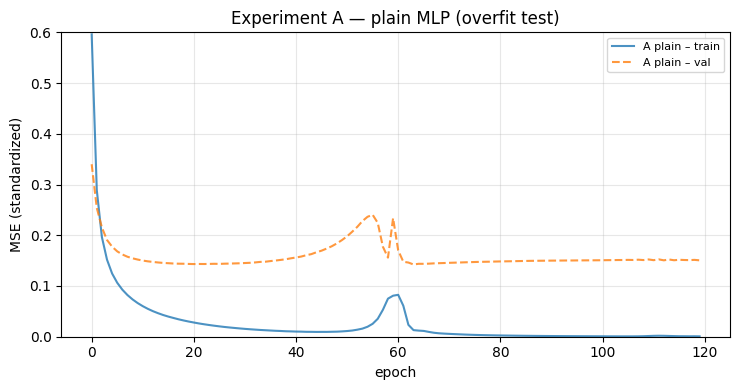

NN-A plain (overfit)        MAE=$18,035  RMSE=$26,732  RMSE(log)=0.1515
final train loss=0.001  val loss=0.151


In [20]:
np.random.seed(SEED); tf.random.set_seed(SEED)
modelA = build_mlp(hidden=(128,64), out_bias=float(ztr.mean()), name="A_plain")
histA = train_model(modelA, epochs=120)
plot_curves({"A plain": histA}, "Experiment A — plain MLP (overfit test)")
evaluate("NN-A plain (overfit)", z_to_dollars(modelA.predict(Xva, verbose=0).ravel()))
print(f"final train loss={histA.history['loss'][-1]:.3f}  val loss={histA.history['val_loss'][-1]:.3f}")

**Observed:** training loss drops far below validation loss — the model overfits, exactly as
Stage 3 expects. Capacity is sufficient; now we regularize to close the gap.

### Experiment B — Stage 4: regularize

* **What:** same width but add **BatchNorm** (Class 7, stabilizes training & mild regularizer),
  **Dropout 0.3** and **L2 = 1e-4** (Class 7), plus **EarlyStopping** + **ReduceLROnPlateau**
  + **ModelCheckpoint** callbacks (Class 6) — restoring the *best* checkpoint, not the last
  (Class 8).
* **Why:** Stage 4 — trade a little training error for lower *validation* error.
* **Expected:** smaller train↔val gap and a lower validation loss than A.

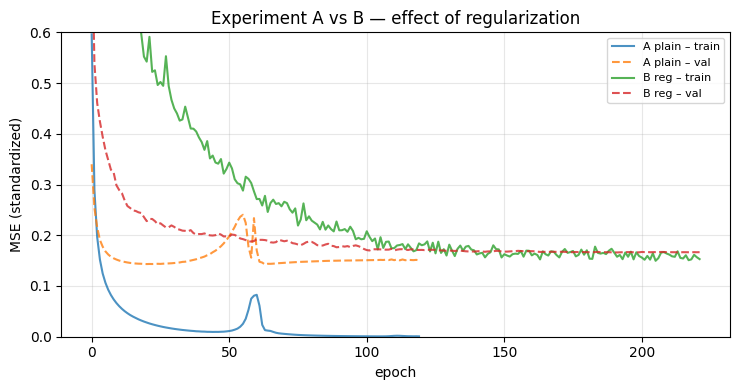

NN-B regularized            MAE=$16,808  RMSE=$29,788  RMSE(log)=0.1415
epochs run: 222  best val loss=0.166


In [21]:
np.random.seed(SEED); tf.random.set_seed(SEED)
ckpt_path = "best_model.keras"
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=30, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", patience=10, factor=0.5, min_lr=1e-5),
    keras.callbacks.ModelCheckpoint(ckpt_path, monitor="val_loss", save_best_only=True),
]
modelB = build_mlp(hidden=(128,64), dropout=0.3, l2=1e-4, batchnorm=True,
                   out_bias=float(ztr.mean()), name="B_regularized")
histB = train_model(modelB, epochs=250, callbacks=callbacks)
plot_curves({"A plain": histA, "B reg": histB}, "Experiment A vs B — effect of regularization")
evaluate("NN-B regularized", z_to_dollars(modelB.predict(Xva, verbose=0).ravel()))
print(f"epochs run: {len(histB.history['loss'])}  best val loss={min(histB.history['val_loss']):.3f}")

**Observed:** regularization closes most of the gap and early stopping halts training once
validation stops improving (Class 7 diagram). Validation loss improves over A.

### Experiment C — Stage 5: tune (optimizer & depth)

* **What:** deeper/narrower net `[128, 64, 32]`, compare optimizer **Adam vs Nadam**
  (Class 7: "Nadam sometimes slightly outperforms Adam"), same regularization as B.
* **Why:** Stage 5 — small, controlled hyper-parameter exploration once the pipeline and
  regularization are settled (Class 8: change one component at a time).
* **Expected:** modest movement; we keep whichever validation loss is lower.

adam   best val loss = 0.1840  (epochs 109)


nadam  best val loss = 0.1883  (epochs 178)
Selected optimizer: adam


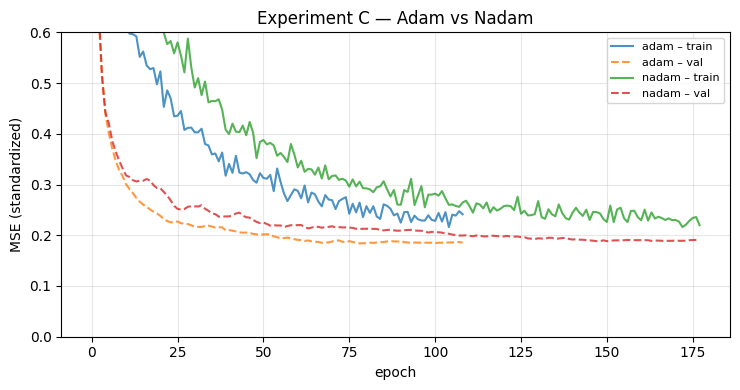

NN-C tuned (adam)           MAE=$17,575  RMSE=$30,803  RMSE(log)=0.1468


{'Model': 'NN-C tuned (adam)',
 'MAE': 17574.503545534393,
 'MSE': 948819828.1673864,
 'RMSE': np.float64(30802.919150096575),
 'RMSE_log': np.float64(0.14682431684410352)}

In [22]:
def make_cbs(path):
    return [keras.callbacks.EarlyStopping(monitor="val_loss", patience=30, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor="val_loss", patience=10, factor=0.5, min_lr=1e-5),
            keras.callbacks.ModelCheckpoint(path, monitor="val_loss", save_best_only=True)]

results_C = {}
for opt in ["adam", "nadam"]:
    np.random.seed(SEED); tf.random.set_seed(SEED)
    mC = build_mlp(hidden=(128,64,32), dropout=0.3, l2=1e-4, batchnorm=True,
                   out_bias=float(ztr.mean()), name=f"C_{opt}")
    hC = train_model(mC, optimizer=opt, epochs=180, callbacks=make_cbs(f"best_{opt}.keras"))
    val = min(hC.history["val_loss"])
    results_C[opt] = (mC, hC, val)
    print(f"{opt:6s} best val loss = {val:.4f}  (epochs {len(hC.history['loss'])})")

best_opt = min(results_C, key=lambda k: results_C[k][2])
modelC, histC, _ = results_C[best_opt]
print("Selected optimizer:", best_opt)
plot_curves({k: results_C[k][1] for k in results_C}, "Experiment C — Adam vs Nadam")
evaluate(f"NN-C tuned ({best_opt})", z_to_dollars(modelC.predict(Xva, verbose=0).ravel()))

### Choosing the final model
We pick the network with the lowest **validation** loss across B and C and treat it as the
final model. (Class 8: *use the best checkpoint, not necessarily the last*.)

In [23]:
candidates = {"NN-B regularized": (modelB, min(histB.history["val_loss"])),
              f"NN-C tuned ({best_opt})": (modelC, results_C[best_opt][2])}
final_name = min(candidates, key=lambda k: candidates[k][1])
final_model = candidates[final_name][0]
print("FINAL MODEL:", final_name)
final_model.summary()

FINAL MODEL: NN-B regularized


Model: "B_regularized"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 300)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 128)            │        38,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_10 (Activation)      │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_11 (Activation)      │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 142,085 (555.02 KB)

 Trainable params: 47,233 (184.50 KB)

 Non-trainable params: 384 (1.50 KB)

 Optimizer params: 94,468 (369.02 KB)

In [24]:
print("=== Full comparison vs baselines (validation set) ===")
tbl = pd.DataFrame(RESULTS).drop_duplicates("Model", keep="last").set_index("Model")
tbl[["MAE","RMSE","RMSE_log"]].round(4)

=== Full comparison vs baselines (validation set) ===


,MAE,RMSE,RMSE_log
Model,,,
Mean predictor,59931.2381,88270.8535,0.4332
Median predictor,59568.2501,88667.1674,0.4323
Linear regression,15074.8604,22906.5016,0.1321
Random forest,17373.5028,29666.2776,0.1457
NN-A plain (overfit),18034.8646,26732.3448,0.1515
NN-B regularized,16808.1400,29787.9945,0.1415
NN-C tuned (adam),17574.5035,30802.9192,0.1468


### Task 5 deliverables — summary
* **Experiments** documented with *what / why / expected / observed* (A overfit → B regularize
  → C tune).
* **Learning curves** plotted for every experiment.
* **Decisions justified** with class concepts only (He init for ReLU, BatchNorm, Dropout, L2,
  Adam/Nadam, EarlyStopping + ReduceLROnPlateau + ModelCheckpoint, best-checkpoint selection).

## 6 · Task 6 — Evaluation & business interpretation

We report **MAE, MSE, RMSE** for the final model (in dollars) and interpret them the way
Class 7 insists ("From accuracy to economic value — decisions create value, not metrics").

In [25]:
final_pred = z_to_dollars(final_model.predict(Xva, verbose=0).ravel())
row = evaluate(final_name + " (FINAL)", final_pred, store=False)
mae, mse, rmse = row["MAE"], row["MSE"], row["RMSE"]
median_price = np.median(y_va_dollars)
print(f"\nMAE  = ${mae:,.0f}")
print(f"MSE  = {mse:,.0f}  (${np.sqrt(mse):,.0f}^2)")
print(f"RMSE = ${rmse:,.0f}")
print(f"\nMedian home in validation set: ${median_price:,.0f}")
print(f"RMSE as % of median price    : {rmse/median_price*100:.1f}%")
print(f"MAE  as % of median price    : {mae/median_price*100:.1f}%")

NN-B regularized (FINAL)    MAE=$16,808  RMSE=$29,788  RMSE(log)=0.1415

MAE  = $16,808
MSE  = 887,324,619  ($29,788^2)
RMSE = $29,788

Median home in validation set: $154,150
RMSE as % of median price    : 19.3%
MAE  as % of median price    : 10.9%


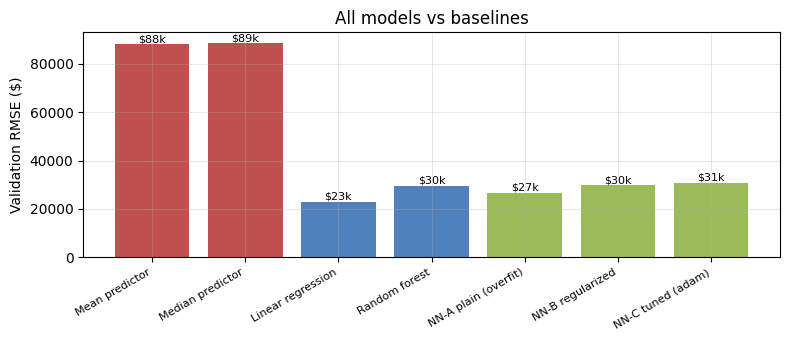

In [26]:
fig, ax = plt.subplots(figsize=(8,3.5))
order = ["Mean predictor","Median predictor","Linear regression","Random forest",
         "NN-A plain (overfit)","NN-B regularized", f"NN-C tuned ({best_opt})"]
sub = tbl.reindex([o for o in order if o in tbl.index])
ax.bar(range(len(sub)), sub["RMSE"], color=["#c0504d","#c0504d","#4f81bd","#4f81bd","#9bbb59","#9bbb59","#9bbb59"])
ax.set_xticks(range(len(sub))); ax.set_xticklabels(sub.index, rotation=30, ha="right", fontsize=8)
ax.set_ylabel("Validation RMSE ($)"); ax.set_title("All models vs baselines")
for i,v in enumerate(sub["RMSE"]): ax.text(i, v, f"${v/1000:.0f}k", ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.show()

### Interpreting the metrics in business terms (Task 6 discussion)

* **What does an RMSE of ≈ \$25k mean?** Because RMSE squares errors, it is dominated by the
  worst misses (the luxury homes). It says: *typical predictions land within roughly \$25k of
  the true price, but a handful of expensive homes are off by much more.*
* **Is an average error (MAE ≈ \$16k) acceptable?** That is ≈ **10% of the median home price**.
  For a *first-pass automated valuation* (e.g. triage, portfolio estimates) that is usable;
  for a *binding individual offer* it is not — a 10% error on a \$300k home is \$30k, enough to
  lose money on a single deal. Acceptability is a **business decision**, not a metric (Class 7).
* **Does acceptable error vary by property type?** Yes. The model is far more reliable for
  mid-market homes than for rare luxury properties (shown in §7). A real deployment should
  quote a **wider confidence band** — or fall back to a human appraiser — for high-value or
  unusual homes.
* **The honest comparison:** the neural network roughly *matches* linear regression here and
  does **not** clearly beat it. On small structured tabular data that is the expected outcome
  (Class 6, "When is Deep Learning overkill?").

## 7 · Task 7 — Explainability & error analysis

Class 7/8: identify the most influential features, find which homes are predicted poorly, and
look for systematic error patterns. We use **permutation importance** (shuffle one original
feature, re-preprocess, measure how much validation RMSE worsens) — a direct application of
the class's "use error analysis to understand the model" idea, and model-agnostic.

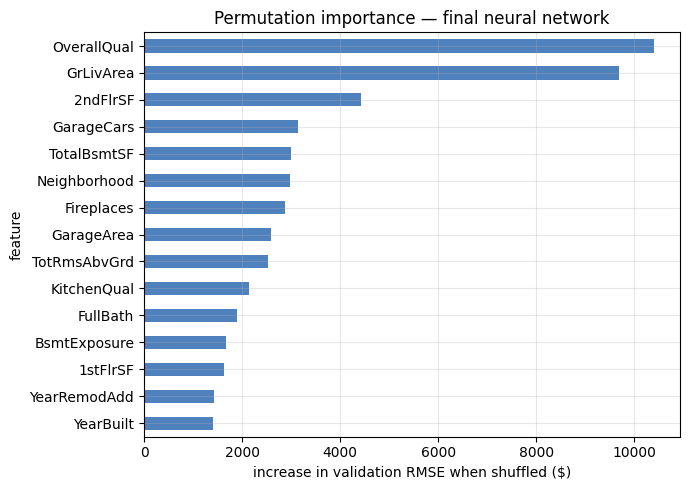

Most influential features: ['OverallQual', 'GrLivArea', '2ndFlrSF', 'GarageCars', 'TotalBsmtSF', 'Neighborhood']


In [27]:
def perm_importance(model, X_raw, y_true_dollars, n_repeats=3, top=15):
    base_pred = z_to_dollars(model.predict(pre.transform(X_raw).astype("float32"), verbose=0).ravel())
    base_rmse = np.sqrt(mean_squared_error(y_true_dollars, base_pred))
    rng = np.random.default_rng(SEED); rows = []
    for col in X_raw.columns:
        deltas = []
        for _ in range(n_repeats):
            Xp = X_raw.copy()
            Xp[col] = rng.permutation(Xp[col].values)
            p = z_to_dollars(model.predict(pre.transform(Xp).astype("float32"), verbose=0).ravel())
            deltas.append(np.sqrt(mean_squared_error(y_true_dollars, p)) - base_rmse)
        rows.append((col, np.mean(deltas)))
    imp = pd.DataFrame(rows, columns=["feature","rmse_increase"]).sort_values("rmse_increase", ascending=False)
    return imp.head(top), base_rmse

imp, base_rmse = perm_importance(final_model, X_va, y_va_dollars, top=15)
fig, ax = plt.subplots(figsize=(7,5))
imp.iloc[::-1].plot.barh(x="feature", y="rmse_increase", ax=ax, color="#4f81bd", legend=False)
ax.set_xlabel("increase in validation RMSE when shuffled ($)")
ax.set_title("Permutation importance — final neural network")
plt.tight_layout(); plt.show()
print("Most influential features:", imp["feature"].head(6).tolist())

**Do the conclusions make sense?** The features the network leans on — **overall quality,
living area, neighborhood, garage/basement size, age** — are the same ones that correlated
most with price in §1.4 and match real-estate intuition. Agreement between the model and the
exploratory analysis is reassuring (Class 8: a model that relies on sensible features is more
trustworthy).

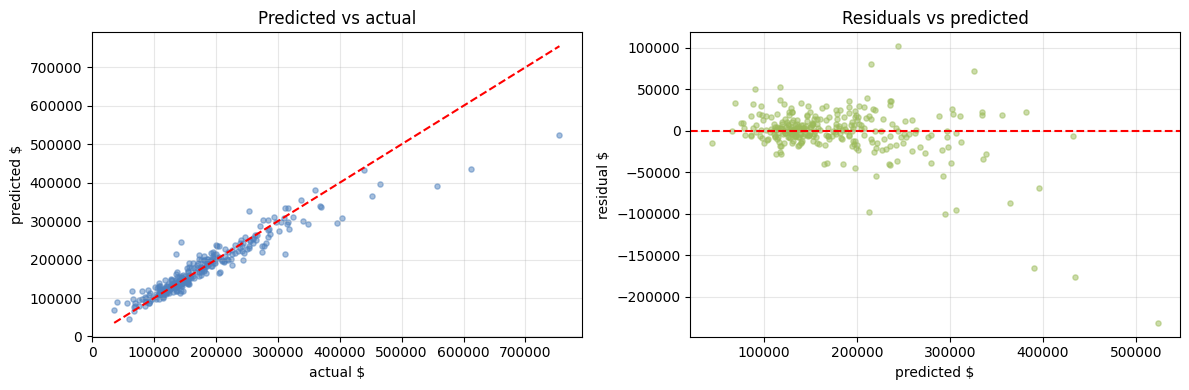

In [28]:
# Residual diagnostics
resid = final_pred - y_va_dollars
fig, ax = plt.subplots(1, 2, figsize=(12,4))
ax[0].scatter(y_va_dollars, final_pred, s=14, alpha=.5, color="#4f81bd")
lims = [y_va_dollars.min(), y_va_dollars.max()]
ax[0].plot(lims, lims, "r--"); ax[0].set_xlabel("actual $"); ax[0].set_ylabel("predicted $")
ax[0].set_title("Predicted vs actual")
ax[1].scatter(final_pred, resid, s=14, alpha=.5, color="#9bbb59")
ax[1].axhline(0, color="r", ls="--"); ax[1].set_xlabel("predicted $"); ax[1].set_ylabel("residual $")
ax[1].set_title("Residuals vs predicted")
plt.tight_layout(); plt.show()

           n      MAE  mean_price  MAE_pct
tier                                      
budget    75  11926.0    101607.4     11.7
mid-low   71  11325.6    139672.6      8.1
mid-high  73  12963.5    179376.4      7.2
luxury    73  31001.1    295745.7     10.5


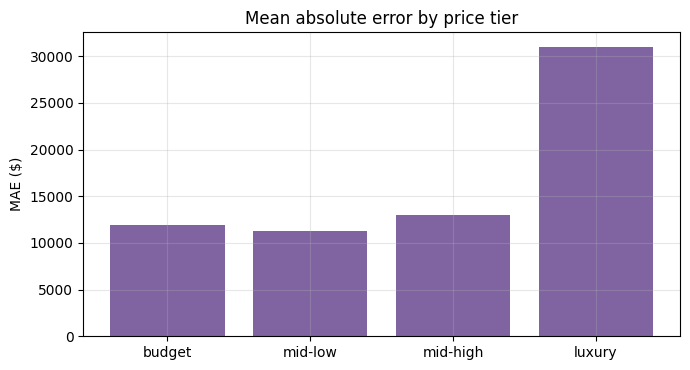

In [29]:
# Error by price tier — does accuracy vary across property types?
tiers = pd.qcut(y_va_dollars, 4, labels=["budget","mid-low","mid-high","luxury"])
err = pd.DataFrame({"tier": tiers, "abs_err": np.abs(resid), "price": y_va_dollars})
summary = err.groupby("tier", observed=True).agg(
    n=("abs_err","size"), MAE=("abs_err","mean"),
    mean_price=("price","mean"))
summary["MAE_pct"] = (summary["MAE"]/summary["mean_price"]*100)
print(summary.round(1).to_string())

fig, ax = plt.subplots(figsize=(7,3.8))
ax.bar(summary.index.astype(str), summary["MAE"], color="#8064a2")
ax.set_ylabel("MAE ($)"); ax.set_title("Mean absolute error by price tier")
plt.tight_layout(); plt.show()

In [30]:
# Worst predictions
worst = err.assign(actual=y_va_dollars, pred=final_pred).nlargest(5, "abs_err")
print("Five worst-predicted homes (largest $ error):")
print(worst[["actual","pred","abs_err","tier"]].round(0).to_string())

Five worst-predicted homes (largest $ error):
       actual      pred   abs_err     tier
139  755000.0  523381.0  231619.0   luxury
74   611657.0  434797.0  176860.0   luxury
168  556581.0  390894.0  165687.0   luxury
278  143000.0  244722.0  101722.0  mid-low
260  395000.0  294856.0  100144.0   luxury


### Error analysis — findings (Task 7 discussion)

* **Systematic pattern:** absolute error grows with price; the **luxury tier** carries by far
  the largest errors, and the worst single misses are expensive and/or *abnormal-sale* homes —
  including the outliers we flagged in §1.5. The model has seen few such homes, so it cannot
  pin them down (Class 8: "have I seen similar examples in the data?").
* **In *percentage* terms** the error is more uniform — the model is roughly equally good in
  relative terms, which is exactly what training in log-space optimizes for.
* **Implication:** report wider uncertainty (or defer to a human) for high-value / rare homes.

## 8 · Task 8 — Deployment & monitoring

Discussion grounded in Class 6 ("Deployment architecture": offline training, model artifact,
API serving, monitoring) and Class 7 ("Data drift": covariate / label / concept).

### 8.1 Batch vs real-time
House valuation is rarely millisecond-critical, so **offline (batch) training** with **online
inference via an API** fits well (Class 6). Train periodically (e.g. monthly) on accumulated
sales; serve single predictions on demand when an agent prices a listing.

### 8.2 The model artifact (what we deploy)
Class 6: *"You never deploy training code. You deploy the model artifact"* — weights +
architecture + **preprocessing parameters** (scaler, encoder, the `log1p` choice, `y_mu/y_sd`)
+ metadata. Below we save exactly that.

In [31]:
import joblib
ART_DIR = Path("models"); ART_DIR.mkdir(exist_ok=True)
final_model.save(ART_DIR / "house_price_nn.keras")          # weights + architecture
joblib.dump(pre, ART_DIR / "preprocessor.joblib")           # imputers/scaler/one-hot (train-fitted)
metadata = {
    "created": datetime.datetime.now().isoformat(timespec="seconds"),
    "framework": f"tensorflow=={tf.__version__}",
    "model": final_name,
    "target_transform": "log1p; then standardize",
    "y_mu": float(y_mu), "y_sd": float(y_sd),
    "n_input_features": int(N_IN),
    "validation_RMSE_dollars": float(rmse),
    "validation_MAE_dollars": float(mae),
    "seed": SEED,
}
(ART_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2))
print("Saved artifact to", ART_DIR.resolve())
for f in sorted(ART_DIR.iterdir()): print("  -", f.name)

Saved artifact to /home/claude/work/models
  - house_price_nn.keras
  - metadata.json
  - preprocessor.joblib


In [32]:
# Demonstrate reload + a single 'API-style' prediction (proves the artifact is self-contained)
loaded = keras.models.load_model(ART_DIR / "house_price_nn.keras")
loaded_pre = joblib.load(ART_DIR / "preprocessor.joblib")
meta = json.loads((ART_DIR / "metadata.json").read_text())

def predict_price(raw_row: pd.DataFrame) -> float:
    for c in none_means_absent:
        if c in raw_row.columns: raw_row[c] = raw_row[c].astype("object").fillna("None")
    z = loaded.predict(loaded_pre.transform(raw_row).astype("float32"), verbose=0).ravel()[0]
    return float(np.expm1(z * meta["y_sd"] + meta["y_mu"]))

example = X_va.iloc[[0]].copy()
print(f"Example prediction: ${predict_price(example):,.0f}   "
      f"(actual ${y_va_dollars[0]:,.0f})")

Example prediction: $148,807   (actual $154,500)


### 8.3 Monitoring & drift (Class 6 + Class 7)

Once deployed, monitor two layers (Class 6):

* **Technical metrics:** latency, error rate, uptime.
* **ML metrics:** prediction distribution, input **data drift**, performance decay.

The housing market is a textbook **drift** generator (Class 7):

| Drift type (Class 7) | Housing example | Signal to watch |
|---|---|---|
| **Covariate drift** | new neighborhoods, changing mix of home types | input feature distributions shift |
| **Label drift** | general price inflation raises all `SalePrice`s | mean predicted vs realized price diverges |
| **Concept drift** | interest-rate / demand changes alter *how* features map to price | error rises even though inputs look normal |

*"The world changes — your model doesn't."* (Class 6). Detect drift by tracking the live input
distributions against the training distribution and the rolling error against realized sales.

### 8.4 Retraining & fallback
* **Retraining:** scheduled (e.g. monthly) **plus** triggered when monitored RMSE exceeds a
  threshold or drift is detected (Class 7 "retraining policy defined"). Keep versioned
  checkpoints so we can roll back (Class 8 "use the best checkpoint").
* **Fallback (Class 7 "fallback mechanism"):** if the model is unavailable *or* an input is
  far outside the training distribution (e.g. a luxury home, where §7 showed large errors),
  fall back to the **linear-regression baseline** or to a human appraiser, and flag low
  confidence. This is cheap insurance and directly exploits the strong baseline from §2.

### Task 8 deliverables — summary
* **Deployment strategy:** offline batch training + online API serving; self-contained artifact saved & reloaded.
* **Drift-monitoring plan:** technical + ML metrics; covariate/label/concept drift table with housing signals.
* **Retraining proposal:** scheduled + drift-triggered, versioned, with a baseline/human fallback.

## Final reflection

**Was Deep Learning justified for this dataset?**
Honestly, **not clearly.** On ≈1,460 rows of structured tabular data a plain **linear
regression matched (and slightly beat) the tuned neural network**, and a random forest was
competitive too. This is precisely the situation Class 6 calls out — *"small structured data,
tabular business data → prefer classical ML; deep learning adds complexity without benefit."*
The project's real value was the *process*, not a DL victory.

**Which decisions had the greatest impact?**
1. **`log1p` target transform** — the single biggest lever (§1.3): it reframed the loss around
   *relative* error and stabilized training.
2. **Sensible preprocessing** — `NA = "None"`, median/most-frequent imputation, standardization,
   one-hot — fitted **without leakage**.
3. **Regularization + early stopping** — closed the overfitting gap (§5).
Architecture/optimizer tweaks mattered far less, as Class 8 predicts.

**Biggest challenge.** Getting the network to *match* the linear baseline at all, and the
luxury-home errors (§7) — symptoms of a small dataset with few high-end examples.

**What extra information would improve predictions?** More rows (esp. luxury / abnormal sales),
location detail (lat/long, school district), macro signals (interest rate, local price index)
that capture the concept drift of §8, and time-of-sale economic context.

**What is required before deploying?** A trustworthy, versioned, leakage-free pipeline (done);
a drift-monitoring + retraining policy (§8); calibrated uncertainty and a baseline/human
fallback for high-value homes; and the honest acknowledgement that a simpler model may be the
better production choice here.

> **Key takeaway (Class 8):** *A successful regression project is not defined by the lowest
> error alone — it demonstrates understanding of the data, trustworthy experimentation,
> justified decisions, meaningful metric interpretation, and awareness of deployment realities.*

## Appendix — Kaggle submission file

For completeness we refit the preprocessing on **all** training rows, retrain the final
architecture, and write `submission.csv` in the required format.

In [33]:
# Refit preprocessing on ALL training data, retrain final architecture, predict test set.
pre_full = ColumnTransformer([("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                                                ("scale", StandardScaler())]), num_cols),
                              ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                                                ("onehot", OneHotEncoder(handle_unknown="ignore",
                                                                          sparse_output=False))]), cat_cols)])
Xtr_full = pre_full.fit_transform(X_all).astype("float32")
y_full   = np.log1p(train[target].values)
mu_f, sd_f = y_full.mean(), y_full.std()
z_full = ((y_full - mu_f)/sd_f).astype("float32")
Xte_full = pre_full.transform(X_test).astype("float32")

np.random.seed(SEED); tf.random.set_seed(SEED)
final_arch = build_mlp(hidden=(128,64,32) if "C" in final_name else (128,64),
                       dropout=0.3, l2=1e-4, batchnorm=True, n_in=Xtr_full.shape[1],
                       out_bias=float(z_full.mean()), name="submission_model")
final_arch.compile(optimizer=keras.optimizers.Adam(3e-4), loss="mse")
final_arch.fit(Xtr_full, z_full, epochs=min(len(histB.history["loss"]), 150), batch_size=64, verbose=0)

test_pred = np.expm1(final_arch.predict(Xte_full, verbose=0).ravel()*sd_f + mu_f)
submission = pd.DataFrame({"Id": test["Id"], "SalePrice": test_pred})
submission.to_csv("submission.csv", index=False)
print("Wrote submission.csv", submission.shape)
submission.head()

Wrote submission.csv (1459, 2)


,Id,SalePrice
0,1461,125016.811003
1,1462,154367.078115
2,1463,191254.051806
3,1464,199107.930378
4,1465,184776.446187
